# 06 — PCA and Clustering Analysis

## From acoustic signal structure to ecological interpretation

### Research objective

This notebook investigates the structure of acoustic variation across the 275-recording
California, Arizona, and Texas dataset after signal processing and acoustic-feature
extraction.

The analysis is designed to answer:

1. How many underlying dimensions are needed to represent the acoustic measurements?
2. Which acoustic feature families contribute most strongly to those dimensions?
3. Do recordings form reproducible groups in acoustic feature space?
4. Are those groups associated with geography, season, recording conditions, or other
   metadata after the unsupervised structure has been discovered?
5. How sensitive are the resulting patterns to choices in feature representation,
   redundancy, and temporal aggregation?

### Unit of analysis

The primary observational unit is the **audio recording**, not the individual
10-second analysis window.

Window-level measurements are retained because they contain information about
within-recording temporal variability. They are not treated as independent ecological
observations.

### Separation of information

The unsupervised feature matrix will contain acoustic measurements only.

The following information will remain outside the feature matrix and will be used
only for post-hoc interpretation:

- species identity
- common and scientific names
- state
- latitude and longitude
- date and season
- recording quality
- QC flags
- recording duration
- acquisition metadata

### Analytical principle

PCA and clustering are exploratory representations of **acoustic structure**.
They are not assumed to measure biodiversity directly.

Any ecological interpretation must therefore be supported by independent metadata
and sensitivity/stability analysis.

### Provenance

Raw audio and metadata are processed in Notebook 05.
This notebook begins from the validated outputs of that workflow and does not alter
the underlying signal-processing decisions.

### Reproducibility

All analytical transformations, feature-selection decisions, random seeds,
aggregation rules, and exported results will be recorded in this notebook.

In [1]:
# =========================================================
# 01. IMPORTS AND REPRODUCIBILITY
# =========================================================

from pathlib import Path
import json
import platform
import sys

import numpy as np
import pandas as pd

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Random seed:", RANDOM_SEED)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Platform: Windows-10-10.0.26200-SP0
Random seed: 42


In [2]:
# =========================================================
# 02. PROJECT ROOT AND DATA DISCOVERY
# =========================================================

PROJECT_ROOT = Path.cwd()

print("Current working directory:")
print(PROJECT_ROOT)

print("\nTop-level contents:")
for item in sorted(PROJECT_ROOT.iterdir()):
    print(" -", item.name)

Current working directory:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\research\notebooks

Top-level contents:
 - .gitkeep
 - 01_api_validation.ipynb
 - 02_data_acquisition.ipynb
 - 03_data_audit.ipynb
 - 04_cleaning.ipynb
 - 05_audio_features.ipynb
 - 06_eda.ipynb
 - 06_PCA_Clustering_Analysis.ipynb


In [3]:
# =========================================================
# 03. PROJECT ROOT AND RESEARCH DATA INVENTORY
# =========================================================

# This notebook lives in:
# <project_root>/research/notebooks/
# Therefore parents[2] should be the project root.

PROJECT_ROOT = PROJECT_ROOT.resolve().parents[1]

print("Project root:")
print(PROJECT_ROOT)

print("\nResearch directory:")
print(PROJECT_ROOT / "research")

# Inventory likely data/output files.
# We deliberately inspect before choosing an input table.

SEARCH_DIRS = [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "research",
    PROJECT_ROOT / "outputs",
]

for directory in SEARCH_DIRS:
    print(f"\n{'=' * 70}")
    print(directory)
    print("=" * 70)

    if not directory.exists():
        print("Directory does not exist.")
        continue

    files_found = sorted(
        p for p in directory.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".csv", ".parquet", ".json"}
        and "node_modules" not in p.parts
    )

    if not files_found:
        print("No CSV/Parquet/JSON files found.")
    else:
        for path in files_found:
            try:
                size_mb = path.stat().st_size / (1024 ** 2)
                relative_path = path.relative_to(PROJECT_ROOT)
                print(f"{relative_path}  [{size_mb:.2f} MB]")
            except Exception:
                print(path)

Project root:
C:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity

Research directory:
C:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\research

C:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data
data\interim\xenocanto_selected\xc_a1_selected_AZ.json  [0.12 MB]
data\interim\xenocanto_selected\xc_a1_selected_CA.json  [0.16 MB]
data\interim\xenocanto_selected\xc_a1_selected_TX.json  [0.15 MB]
data\manifests\a1_xenocanto_selection_manifest.csv  [0.06 MB]
data\manifests\cleaning_log.csv  [0.04 MB]
data\manifests\feature_manifest.csv  [0.01 MB]
data\processed\acoustic_features_recording.csv  [0.43 MB]
data\processed\acoustic_features_window.csv  [1.22 MB]
data\processed\cleaning_summary.csv  [0.00 MB]
data\processed\ebird_observations.csv  [0.37 MB]
data\processed\master_metadata.csv  [0.12 MB]
data\raw\ebird\ebird_observations_raw_AZ.json  [0.14 MB]
data\raw\ebird\ebird_observations_raw_CA.json  [0.19 MB]
data\raw\ebird\ebird_observations_raw_TX.json

In [4]:
# =========================================================
# 04. INSPECT PROCESSED FEATURE EXPORTS
# =========================================================

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Processed directory:")
print(PROCESSED_DIR)

print("\nFiles/directories:")
for path in sorted(PROCESSED_DIR.iterdir()):
    print(f" - {path.name}  |  directory={path.is_dir()}")

print("\nPotential acoustic feature files:")
for path in sorted(PROCESSED_DIR.rglob("*")):
    if "acoustic" in path.name.lower() or "feature" in path.name.lower():
        print(
            f" - {path.relative_to(PROJECT_ROOT)}"
            f"  | directory={path.is_dir()}"
            f"  | size={path.stat().st_size / (1024**2):.2f} MB"
            if path.is_file()
            else f" - {path.relative_to(PROJECT_ROOT)} | directory=True"
        )

Processed directory:
C:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed

Files/directories:
 - .gitkeep  |  directory=False
 - acoustic_features_recording.csv  |  directory=False
 - acoustic_features_window.csv  |  directory=False
 - cleaning_summary.csv  |  directory=False
 - ebird_observations.csv  |  directory=False
 - master_metadata.csv  |  directory=False

Potential acoustic feature files:
 - data\processed\acoustic_features_recording.csv  | directory=False  | size=0.43 MB
 - data\processed\acoustic_features_window.csv  | directory=False  | size=1.22 MB


In [5]:
# =========================================================
# 05. INSPECT RECORDING-LEVEL FEATURE TABLE
# =========================================================

RECORDING_FEATURE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "acoustic_features_recording.csv"
)

if not RECORDING_FEATURE_PATH.exists():
    raise FileNotFoundError(
        f"Expected recording-level feature table was not found:\n"
        f"{RECORDING_FEATURE_PATH}"
    )

recording_features = pd.read_csv(RECORDING_FEATURE_PATH)

print("Shape:", recording_features.shape)

print("\nColumns:")
for i, col in enumerate(recording_features.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nFirst 3 rows:")
display(recording_features.head(3))

Shape: (275, 114)

Columns:
01. recording_id
02. state
03. species_id
04. common_name
05. scientific_name
06. original_sample_rate
07. original_channels
08. flag_short_duration
09. flag_low_amplitude
10. flag_clipping
11. flag_low_quality
12. flag_any
13. flag_bandlimit_incompatible
14. n_windows
15. aci_mean
16. adi_mean
17. bioacoustic_index_mean
18. ndsi_mean
19. ndsi_ratio_ba_mean
20. anthropophony_mean
21. biophony_mean
22. spectral_entropy_eas_mean
23. spectral_entropy_ecu_mean
24. spectral_entropy_ecv_mean
25. spectral_entropy_eps_mean
26. spectral_entropy_eps_kurt_mean
27. spectral_entropy_eps_skew_mean
28. temporal_entropy_mean
29. rms_mean_mean
30. rms_std_mean
31. zcr_mean_mean
32. zcr_std_mean
33. spectral_centroid_mean_mean
34. spectral_centroid_std_mean
35. spectral_bandwidth_mean_mean
36. spectral_bandwidth_std_mean
37. spectral_rolloff_mean_mean
38. spectral_rolloff_std_mean
39. mfcc_01_mean
40. mfcc_01_within_std_mean
41. mfcc_02_mean
42. mfcc_02_within_std_mean
43. mf

,recording_id,state,species_id,common_name,scientific_name,original_sample_rate,original_channels,flag_short_duration,flag_low_amplitude,flag_clipping,...,mfcc_09_between_window_std,mfcc_09_within_std_std,mfcc_10_between_window_std,mfcc_10_within_std_std,mfcc_11_between_window_std,mfcc_11_within_std_std,mfcc_12_between_window_std,mfcc_12_within_std_std,mfcc_13_between_window_std,mfcc_13_within_std_std
0,1035206,AZ,Chordeiles acutipennis,Lesser Nighthawk,Chordeiles acutipennis,48000,2,False,False,False,...,1.461684,0.824667,0.837081,0.596059,0.754081,0.719955,1.332288,0.391086,0.668143,0.441963
1,1080401,AZ,Callipepla gambelii,Gambel's Quail,Callipepla gambelii,48000,2,False,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1080405,AZ,Callipepla squamata,Scaled Quail,Callipepla squamata,48000,2,False,False,False,...,3.185878,1.569469,2.218685,0.821447,2.356698,0.833393,1.727223,0.875944,1.840346,0.860789


In [6]:
# =========================================================
# 06. RECORDING-LEVEL FEATURE REPRESENTATION AUDIT
# =========================================================

# ---------------------------------------------------------
# 1. Identify metadata / acoustic feature columns
# ---------------------------------------------------------

metadata_cols = [
    "recording_id",
    "state",
    "species_id",
    "common_name",
    "scientific_name",
    "original_sample_rate",
    "original_channels",
    "flag_short_duration",
    "flag_low_amplitude",
    "flag_clipping",
    "flag_low_quality",
    "flag_any",
    "flag_bandlimit_incompatible",
    "n_windows",
]

acoustic_cols = [
    c for c in recording_features.columns
    if c not in metadata_cols
]

print("Total columns:", recording_features.shape[1])
print("Metadata columns:", len(metadata_cols))
print("Acoustic/statistical columns:", len(acoustic_cols))


# ---------------------------------------------------------
# 2. Classify acoustic columns by representation
# ---------------------------------------------------------

mean_cols = [
    c for c in acoustic_cols
    if c.endswith("_mean")
]

between_cols = [
    c for c in acoustic_cols
    if c.endswith("_between_window_std")
]

within_cols = [
    c for c in acoustic_cols
    if c.endswith("_within_std_std")
]

other_acoustic_cols = [
    c for c in acoustic_cols
    if c not in mean_cols + between_cols + within_cols
]

print("\nFeature representation:")
print(" - Mean features:", len(mean_cols))
print(" - Between-window variability:", len(between_cols))
print(" - Within-window variability:", len(within_cols))
print(" - Other acoustic/statistical columns:", len(other_acoustic_cols))

if other_acoustic_cols:
    print("\nOther acoustic/statistical columns:")
    for c in other_acoustic_cols:
        print("  ", c)


# ---------------------------------------------------------
# 3. Window-count structure
# ---------------------------------------------------------

print("\nWindow-count distribution:")
print(
    recording_features["n_windows"]
    .value_counts()
    .sort_index()
)

print(
    "\nRecordings with exactly one window:",
    (recording_features["n_windows"] == 1).sum()
)

print(
    "Recordings with >1 window:",
    (recording_features["n_windows"] > 1).sum()
)


# ---------------------------------------------------------
# 4. Missingness by feature representation
# ---------------------------------------------------------

print("\nMissing values:")
print("Mean features:",
      int(recording_features[mean_cols].isna().sum().sum()))

print("Between-window features:",
      int(recording_features[between_cols].isna().sum().sum()))

print("Within-window features:",
      int(recording_features[within_cols].isna().sum().sum()))


# ---------------------------------------------------------
# 5. Check whether variability missingness is explained
#    entirely by single-window recordings
# ---------------------------------------------------------

single_window = recording_features["n_windows"] == 1
multi_window = recording_features["n_windows"] > 1

print("\nVariability completeness:")
print(
    "Single-window recordings with any between-window NaN:",
    recording_features.loc[single_window, between_cols]
    .isna()
    .any(axis=1)
    .sum()
)

print(
    "Multi-window recordings with any between-window NaN:",
    recording_features.loc[multi_window, between_cols]
    .isna()
    .any(axis=1)
    .sum()
)

print(
    "Single-window recordings with any within-window NaN:",
    recording_features.loc[single_window, within_cols]
    .isna()
    .any(axis=1)
    .sum()
)

print(
    "Multi-window recordings with any within-window NaN:",
    recording_features.loc[multi_window, within_cols]
    .isna()
    .any(axis=1)
    .sum()
)


# ---------------------------------------------------------
# 6. Check feature-level missingness
# ---------------------------------------------------------

missing_summary = (
    recording_features[acoustic_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nFeatures with missing values:")
display(missing_summary[missing_summary > 0].to_frame("n_missing"))

Total columns: 114
Metadata columns: 14
Acoustic/statistical columns: 100

Feature representation:
 - Mean features: 50
 - Between-window variability: 13
 - Within-window variability: 13
 - Other acoustic/statistical columns: 24

Other acoustic/statistical columns:
   aci_std
   adi_std
   bioacoustic_index_std
   ndsi_std
   ndsi_ratio_ba_std
   anthropophony_std
   biophony_std
   spectral_entropy_eas_std
   spectral_entropy_ecu_std
   spectral_entropy_ecv_std
   spectral_entropy_eps_std
   spectral_entropy_eps_kurt_std
   spectral_entropy_eps_skew_std
   temporal_entropy_std
   rms_mean_std
   rms_std_std
   zcr_mean_std
   zcr_std_std
   spectral_centroid_mean_std
   spectral_centroid_std_std
   spectral_bandwidth_mean_std
   spectral_bandwidth_std_std
   spectral_rolloff_mean_std
   spectral_rolloff_std_std

Window-count distribution:
n_windows
1     117
2      39
3      25
4      22
5      15
6      12
7       7
8       5
9       1
10      4
11      5
12      2
13      1
14      

,n_missing
mfcc_07_within_std_std,117
mfcc_07_between_window_std,117
mfcc_06_within_std_std,117
mfcc_06_between_window_std,117
spectral_centroid_mean_std,117
spectral_centroid_std_std,117
spectral_bandwidth_mean_std,117
spectral_bandwidth_std_std,117
spectral_rolloff_mean_std,117
spectral_rolloff_std_std,117


In [7]:
# =========================================================
# 07. COMPLETE ACOUSTIC FEATURE INVENTORY
# =========================================================

print("=" * 80)
print("ALL 100 ACOUSTIC / STATISTICAL COLUMNS")
print("=" * 80)

for i, col in enumerate(acoustic_cols, start=1):
    print(f"{i:03d}. {col}")


# ---------------------------------------------------------
# Missingness by feature
# ---------------------------------------------------------

missing_by_feature = (
    recording_features[acoustic_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\n" + "=" * 80)
print("MISSINGNESS BY FEATURE")
print("=" * 80)

for col, n_missing in missing_by_feature.items():
    if n_missing > 0:
        print(
            f"{col:<45} "
            f"{n_missing:>4} missing "
            f"({100 * n_missing / len(recording_features):5.1f}%)"
        )


# ---------------------------------------------------------
# Group columns by naming pattern
# ---------------------------------------------------------

feature_groups = {
    "mean": mean_cols,
    "between_window_std": between_cols,
    "within_window_std": within_cols,
    "other": other_acoustic_cols,
}

print("\n" + "=" * 80)
print("FEATURE GROUP COUNTS")
print("=" * 80)

for group, cols in feature_groups.items():
    print(f"{group:<25}: {len(cols)}")


# ---------------------------------------------------------
# Missingness by recording type
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("MISSINGNESS BY RECORDING TYPE")
print("=" * 80)

for label, mask in [
    ("Single-window", recording_features["n_windows"] == 1),
    ("Multi-window", recording_features["n_windows"] > 1),
]:
    subset = recording_features.loc[mask, acoustic_cols]

    print(f"\n{label} recordings: {len(subset)}")

    missing_features = subset.isna().sum()

    if (missing_features > 0).any():
        display(
            missing_features[missing_features > 0]
            .to_frame("n_missing")
        )
    else:
        print("No missing acoustic values.")

ALL 100 ACOUSTIC / STATISTICAL COLUMNS
001. aci_mean
002. adi_mean
003. bioacoustic_index_mean
004. ndsi_mean
005. ndsi_ratio_ba_mean
006. anthropophony_mean
007. biophony_mean
008. spectral_entropy_eas_mean
009. spectral_entropy_ecu_mean
010. spectral_entropy_ecv_mean
011. spectral_entropy_eps_mean
012. spectral_entropy_eps_kurt_mean
013. spectral_entropy_eps_skew_mean
014. temporal_entropy_mean
015. rms_mean_mean
016. rms_std_mean
017. zcr_mean_mean
018. zcr_std_mean
019. spectral_centroid_mean_mean
020. spectral_centroid_std_mean
021. spectral_bandwidth_mean_mean
022. spectral_bandwidth_std_mean
023. spectral_rolloff_mean_mean
024. spectral_rolloff_std_mean
025. mfcc_01_mean
026. mfcc_01_within_std_mean
027. mfcc_02_mean
028. mfcc_02_within_std_mean
029. mfcc_03_mean
030. mfcc_03_within_std_mean
031. mfcc_04_mean
032. mfcc_04_within_std_mean
033. mfcc_05_mean
034. mfcc_05_within_std_mean
035. mfcc_06_mean
036. mfcc_06_within_std_mean
037. mfcc_07_mean
038. mfcc_07_within_std_mean
03

,n_missing
aci_std,117
adi_std,117
bioacoustic_index_std,117
ndsi_std,117
ndsi_ratio_ba_std,117
anthropophony_std,117
biophony_std,117
spectral_entropy_eas_std,117
spectral_entropy_ecu_std,117
spectral_entropy_ecv_std,117



Multi-window recordings: 158
No missing acoustic values.


In [8]:
# =========================================================
# 08. PRIMARY ANALYSIS MATRIX
# =========================================================

# Primary representation:
# one row per recording
# 50 mean acoustic features
# no ecological labels or metadata

PRIMARY_FEATURES = mean_cols.copy()

X_primary = recording_features[PRIMARY_FEATURES].copy()

print("Primary feature matrix shape:", X_primary.shape)

print("\nExpected:")
print(" - recordings:", len(recording_features))
print(" - features:", len(PRIMARY_FEATURES))

print("\nMissing values:")
print(int(X_primary.isna().sum().sum()))

print("\nNon-finite values:")
print(int((~np.isfinite(X_primary)).sum().sum()))

print("\nZero-variance features:")
zero_variance = X_primary.std()
print(zero_variance[zero_variance == 0])

print("\nPrimary feature list:")
for i, col in enumerate(PRIMARY_FEATURES, start=1):
    print(f"{i:02d}. {col}")

Primary feature matrix shape: (275, 50)

Expected:
 - recordings: 275
 - features: 50

Missing values:
0

Non-finite values:
0

Zero-variance features:
Series([], dtype: float64)

Primary feature list:
01. aci_mean
02. adi_mean
03. bioacoustic_index_mean
04. ndsi_mean
05. ndsi_ratio_ba_mean
06. anthropophony_mean
07. biophony_mean
08. spectral_entropy_eas_mean
09. spectral_entropy_ecu_mean
10. spectral_entropy_ecv_mean
11. spectral_entropy_eps_mean
12. spectral_entropy_eps_kurt_mean
13. spectral_entropy_eps_skew_mean
14. temporal_entropy_mean
15. rms_mean_mean
16. rms_std_mean
17. zcr_mean_mean
18. zcr_std_mean
19. spectral_centroid_mean_mean
20. spectral_centroid_std_mean
21. spectral_bandwidth_mean_mean
22. spectral_bandwidth_std_mean
23. spectral_rolloff_mean_mean
24. spectral_rolloff_std_mean
25. mfcc_01_mean
26. mfcc_01_within_std_mean
27. mfcc_02_mean
28. mfcc_02_within_std_mean
29. mfcc_03_mean
30. mfcc_03_within_std_mean
31. mfcc_04_mean
32. mfcc_04_within_std_mean
33. mfcc_05_

In [9]:
# =========================================================
# 09. PRIMARY FEATURE DISTRIBUTION AUDIT
# =========================================================

distribution_summary = pd.DataFrame({
    "mean": X_primary.mean(),
    "std": X_primary.std(),
    "min": X_primary.min(),
    "median": X_primary.median(),
    "max": X_primary.max(),
    "skew": X_primary.skew(),
    "n_unique": X_primary.nunique(),
}).sort_values("skew", key=lambda x: x.abs(), ascending=False)

display(distribution_summary)

,mean,std,min,median,max,skew,n_unique
ndsi_ratio_ba_mean,204.513513,2.409964e+03,0.000203,1.601007,3.958200e+04,16.077034,275
biophony_mean,280265.028262,5.660700e+05,20.704662,78040.448381,6.544147e+06,6.054621,275
spectral_entropy_eps_kurt_mean,74.690762,9.178627e+01,8.818353,49.489501,8.160325e+02,5.125216,275
anthropophony_mean,356300.319742,1.076080e+06,1.208248,34159.169434,7.599650e+06,4.851599,275
bioacoustic_index_mean,990.799185,7.359337e+02,124.918991,862.284263,7.573534e+03,4.455467,275
rms_mean_mean,0.022136,2.739879e-02,0.000404,0.012651,2.290608e-01,3.597171,275
spectral_entropy_eps_skew_mean,6.788540,3.408495e+00,2.298507,5.934177,2.840173e+01,2.820090,275
mfcc_13_mean,0.302657,2.711732e+00,-8.767452,-0.033158,2.126270e+01,2.581803,275
mfcc_12_within_std_mean,3.898513,1.441049e+00,1.507575,3.702370,1.202904e+01,1.578463,275
rms_std_mean,0.019834,1.798209e-02,0.000206,0.014060,9.976808e-02,1.536816,275


In [10]:
# ============================================================
# Cell 11 — Feature-definition and transformation audit
# ============================================================
#
# Purpose:
#   Classify the 50 primary acoustic features according to their
#   mathematical/distributional structure before PCA.
#
# Important:
#   No transformation is applied in this cell.
#   This is an audit only.
#
# Rationale:
#   PCA is variance-based, so extreme skew and heavy-tailed
#   variables can disproportionately influence the covariance
#   structure. However, transformations must respect the meaning
#   and support of each feature.
# ============================================================

feature_audit = pd.DataFrame(index=PRIMARY_FEATURES)

# ------------------------------------------------------------
# 1. Feature families
# ------------------------------------------------------------

def classify_feature(feature):
    if feature.startswith("mfcc_"):
        return "MFCC"

    if feature.startswith("aci_"):
        return "Acoustic complexity"

    if feature.startswith("adi_"):
        return "Acoustic diversity"

    if feature.startswith("bioacoustic_index_"):
        return "Bioacoustic index"

    if feature.startswith("ndsi_"):
        return "NDSI / soundscape ratio"

    if feature.startswith("anthropophony_"):
        return "Anthropophony energy"

    if feature.startswith("biophony_"):
        return "Biophony energy"

    if feature.startswith("spectral_entropy_"):
        return "Spectral entropy / higher moments"

    if feature.startswith("rms_"):
        return "Amplitude / RMS"

    if feature.startswith("zcr_"):
        return "Zero-crossing rate"

    if feature.startswith("spectral_centroid_"):
        return "Spectral centroid"

    if feature.startswith("spectral_bandwidth_"):
        return "Spectral bandwidth"

    if feature.startswith("spectral_rolloff_"):
        return "Spectral rolloff"

    return "Other"


feature_audit["family"] = [
    classify_feature(f) for f in PRIMARY_FEATURES
]


# ------------------------------------------------------------
# 2. Empirical support and distribution diagnostics
# ------------------------------------------------------------

feature_audit["min"] = X_primary.min()
feature_audit["max"] = X_primary.max()
feature_audit["median"] = X_primary.median()
feature_audit["mean"] = X_primary.mean()
feature_audit["std"] = X_primary.std()
feature_audit["skew"] = X_primary.skew()

feature_audit["has_negative"] = (
    X_primary.min() < 0
)

feature_audit["has_zero"] = (
    (X_primary == 0).any()
)

feature_audit["strictly_positive"] = (
    X_primary.min() > 0
)

feature_audit["bounded_minus1_1"] = (
    (X_primary.min() >= -1) &
    (X_primary.max() <= 1)
)

feature_audit["bounded_0_1"] = (
    (X_primary.min() >= 0) &
    (X_primary.max() <= 1)
)


# ------------------------------------------------------------
# 3. Candidate transformation logic
# ------------------------------------------------------------
#
# These are CANDIDATES, not final decisions.
#
# We deliberately do not automatically log-transform everything.
# ------------------------------------------------------------

def candidate_transform(row):

    f = row.name
    mn = row["min"]
    sk = row["skew"]

    # NDSI is mathematically bounded [-1, 1].
    # Do not log-transform.
    if f == "ndsi_mean":
        return "none"

    # rBA is a positive ratio and can become extremely large
    # when anthropophonic energy approaches zero.
    if f == "ndsi_ratio_ba_mean":
        return "log1p"

    # Energy-like positive variables are candidates for a
    # logarithmic transformation when strongly right-skewed.
    if (
        row["strictly_positive"]
        and sk > 2
    ):
        return "log"

    # Nonnegative variables with zeros can use log1p if
    # strongly right-skewed.
    if (
        row["has_zero"]
        and mn >= 0
        and sk > 2
    ):
        return "log1p"

    # Signed variables should not receive a simple log.
    if row["has_negative"]:
        return "none"

    # Moderate skew: retain initially.
    return "none"


feature_audit["candidate_transform"] = feature_audit.apply(
    candidate_transform,
    axis=1
)


# ------------------------------------------------------------
# 4. Print audit table
# ------------------------------------------------------------

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)

display(
    feature_audit.sort_values(
        by="skew",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,family,min,max,median,mean,std,skew,has_negative,has_zero,strictly_positive,bounded_minus1_1,bounded_0_1,candidate_transform
ndsi_ratio_ba_mean,NDSI / soundscape ratio,0.000203,3.958200e+04,1.601007,204.513513,2.409964e+03,16.077034,False,False,True,False,False,log1p
biophony_mean,Biophony energy,20.704662,6.544147e+06,78040.448381,280265.028262,5.660700e+05,6.054621,False,False,True,False,False,log
spectral_entropy_eps_kurt_mean,Spectral entropy / higher moments,8.818353,8.160325e+02,49.489501,74.690762,9.178627e+01,5.125216,False,False,True,False,False,log
anthropophony_mean,Anthropophony energy,1.208248,7.599650e+06,34159.169434,356300.319742,1.076080e+06,4.851599,False,False,True,False,False,log
bioacoustic_index_mean,Bioacoustic index,124.918991,7.573534e+03,862.284263,990.799185,7.359337e+02,4.455467,False,False,True,False,False,log
rms_mean_mean,Amplitude / RMS,0.000404,2.290608e-01,0.012651,0.022136,2.739879e-02,3.597171,False,False,True,True,True,log
spectral_entropy_eps_skew_mean,Spectral entropy / higher moments,2.298507,2.840173e+01,5.934177,6.788540,3.408495e+00,2.820090,False,False,True,False,False,log
mfcc_13_mean,MFCC,-8.767452,2.126270e+01,-0.033158,0.302657,2.711732e+00,2.581803,True,False,False,False,False,none
mfcc_12_within_std_mean,MFCC,1.507575,1.202904e+01,3.702370,3.898513,1.441049e+00,1.578463,False,False,True,False,False,none
rms_std_mean,Amplitude / RMS,0.000206,9.976808e-02,0.014060,0.019834,1.798209e-02,1.536816,False,False,True,True,True,none


In [11]:
# ============================================================
# Cell 12 — Transformation audit summary
# ============================================================

print("FEATURE TRANSFORMATION AUDIT")
print("=" * 70)

print("\nCandidate transformations:")
display(
    feature_audit[
        [
            "family",
            "min",
            "max",
            "skew",
            "has_negative",
            "strictly_positive",
            "bounded_minus1_1",
            "candidate_transform"
        ]
    ]
    .query("candidate_transform != 'none'")
    .sort_values("skew", ascending=False)
)

print("\nFeature counts by candidate transformation:")
display(
    feature_audit["candidate_transform"]
    .value_counts()
    .rename_axis("candidate_transform")
    .to_frame("n_features")
)

print("\nStrongly skewed features (|skew| > 2):")
display(
    feature_audit[
        feature_audit["skew"].abs() > 2
    ][
        [
            "family",
            "min",
            "max",
            "skew",
            "has_negative",
            "strictly_positive",
            "candidate_transform"
        ]
    ]
    .sort_values("skew", ascending=False)
)

FEATURE TRANSFORMATION AUDIT

Candidate transformations:


,family,min,max,skew,has_negative,strictly_positive,bounded_minus1_1,candidate_transform
ndsi_ratio_ba_mean,NDSI / soundscape ratio,0.000203,3.958200e+04,16.077034,False,True,False,log1p
biophony_mean,Biophony energy,20.704662,6.544147e+06,6.054621,False,True,False,log
spectral_entropy_eps_kurt_mean,Spectral entropy / higher moments,8.818353,8.160325e+02,5.125216,False,True,False,log
anthropophony_mean,Anthropophony energy,1.208248,7.599650e+06,4.851599,False,True,False,log
bioacoustic_index_mean,Bioacoustic index,124.918991,7.573534e+03,4.455467,False,True,False,log
rms_mean_mean,Amplitude / RMS,0.000404,2.290608e-01,3.597171,False,True,True,log
spectral_entropy_eps_skew_mean,Spectral entropy / higher moments,2.298507,2.840173e+01,2.820090,False,True,False,log



Feature counts by candidate transformation:


,n_features
candidate_transform,
none,43
log,6
log1p,1



Strongly skewed features (|skew| > 2):


,family,min,max,skew,has_negative,strictly_positive,candidate_transform
ndsi_ratio_ba_mean,NDSI / soundscape ratio,0.000203,3.958200e+04,16.077034,False,True,log1p
biophony_mean,Biophony energy,20.704662,6.544147e+06,6.054621,False,True,log
spectral_entropy_eps_kurt_mean,Spectral entropy / higher moments,8.818353,8.160325e+02,5.125216,False,True,log
anthropophony_mean,Anthropophony energy,1.208248,7.599650e+06,4.851599,False,True,log
bioacoustic_index_mean,Bioacoustic index,124.918991,7.573534e+03,4.455467,False,True,log
rms_mean_mean,Amplitude / RMS,0.000404,2.290608e-01,3.597171,False,True,log
spectral_entropy_eps_skew_mean,Spectral entropy / higher moments,2.298507,2.840173e+01,2.820090,False,True,log
mfcc_13_mean,MFCC,-8.767452,2.126270e+01,2.581803,True,False,none


In [12]:
# ============================================================
# Cell 13 — Construct PCA sensitivity representations
# ============================================================
#
# Two representations are retained:
#
# A. Baseline:
#    Original recording-level features + standardization
#
# B. Distribution-aware:
#    Targeted transformations for strongly right-skewed,
#    positive-valued features + standardization
#
# No observations are removed and no missing values are imputed.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Copy the primary recording-level feature matrix
# ------------------------------------------------------------

X_baseline = X_primary.copy()
X_transformed = X_primary.copy()


# ------------------------------------------------------------
# 2. Define transformations based on the audit
# ------------------------------------------------------------

LOG1P_FEATURES = [
    "ndsi_ratio_ba_mean",
]

LOG_FEATURES = [
    "biophony_mean",
    "anthropophony_mean",
    "bioacoustic_index_mean",
    "rms_mean_mean",
    "spectral_entropy_eps_kurt_mean",
    "spectral_entropy_eps_skew_mean",
]


# ------------------------------------------------------------
# 3. Apply transformations
# ------------------------------------------------------------

for feature in LOG1P_FEATURES:
    X_transformed[feature] = np.log1p(
        X_transformed[feature]
    )

for feature in LOG_FEATURES:
    X_transformed[feature] = np.log(
        X_transformed[feature]
    )


# ------------------------------------------------------------
# 4. Validate transformation
# ------------------------------------------------------------

assert np.isfinite(X_baseline.to_numpy()).all()
assert np.isfinite(X_transformed.to_numpy()).all()

assert X_baseline.shape == X_transformed.shape
assert X_baseline.columns.tolist() == X_transformed.columns.tolist()


# ------------------------------------------------------------
# 5. Standardize only AFTER transformations
# ------------------------------------------------------------

scaler_baseline = StandardScaler()
scaler_transformed = StandardScaler()

X_baseline_scaled = scaler_baseline.fit_transform(
    X_baseline
)

X_transformed_scaled = scaler_transformed.fit_transform(
    X_transformed
)


# ------------------------------------------------------------
# 6. Verify standardization
# ------------------------------------------------------------

baseline_means = X_baseline_scaled.mean(axis=0)
baseline_stds = X_baseline_scaled.std(axis=0)

transformed_means = X_transformed_scaled.mean(axis=0)
transformed_stds = X_transformed_scaled.std(axis=0)

print("BASELINE REPRESENTATION")
print("-" * 60)
print("Shape:", X_baseline_scaled.shape)
print("Maximum absolute feature mean:",
      np.max(np.abs(baseline_means)))
print("Maximum |std - 1|:",
      np.max(np.abs(baseline_stds - 1)))


print("\nDISTRIBUTION-AWARE REPRESENTATION")
print("-" * 60)
print("Shape:", X_transformed_scaled.shape)
print("Maximum absolute feature mean:",
      np.max(np.abs(transformed_means)))
print("Maximum |std - 1|:",
      np.max(np.abs(transformed_stds - 1)))


print("\nTransformed features:")
print("log1p:", LOG1P_FEATURES)
print("log:", LOG_FEATURES)

BASELINE REPRESENTATION
------------------------------------------------------------
Shape: (275, 50)
Maximum absolute feature mean: 6.653263798480939e-16
Maximum |std - 1|: 2.220446049250313e-16

DISTRIBUTION-AWARE REPRESENTATION
------------------------------------------------------------
Shape: (275, 50)
Maximum absolute feature mean: 6.653263798480939e-16
Maximum |std - 1|: 2.220446049250313e-16

Transformed features:
log1p: ['ndsi_ratio_ba_mean']
log: ['biophony_mean', 'anthropophony_mean', 'bioacoustic_index_mean', 'rms_mean_mean', 'spectral_entropy_eps_kurt_mean', 'spectral_entropy_eps_skew_mean']


In [13]:
# ============================================================
# PCA COMPARISON: BASELINE VS DISTRIBUTION-AWARE
# ============================================================

pca_baseline = PCA(random_state=RANDOM_SEED)
pca_transformed = PCA(random_state=RANDOM_SEED)

X_baseline_pca = pca_baseline.fit_transform(X_baseline_scaled)
X_transformed_pca = pca_transformed.fit_transform(X_transformed_scaled)

# ------------------------------------------------------------
# Explained variance
# ------------------------------------------------------------

explained_baseline = pca_baseline.explained_variance_ratio_
explained_transformed = pca_transformed.explained_variance_ratio_

cumulative_baseline = np.cumsum(explained_baseline)
cumulative_transformed = np.cumsum(explained_transformed)

pca_comparison = pd.DataFrame({
    "PC": np.arange(1, len(explained_baseline) + 1),
    "Baseline_Explained": explained_baseline,
    "Baseline_Cumulative": cumulative_baseline,
    "Transformed_Explained": explained_transformed,
    "Transformed_Cumulative": cumulative_transformed,
})

print("=" * 70)
print("PCA EXPLAINED VARIANCE COMPARISON")
print("=" * 70)

display(pca_comparison.head(10).round(4))

print("\nCumulative variance:")
for k in [2, 3, 5, 10]:
    print(
        f"PC1-{k}: "
        f"Baseline = {cumulative_baseline[k-1]:.4f} | "
        f"Distribution-aware = {cumulative_transformed[k-1]:.4f}"
    )

# ------------------------------------------------------------
# Compare PC1-PC2 geometry
# ------------------------------------------------------------

pc12_correlation = np.corrcoef(
    X_baseline_pca[:, :2].ravel(),
    X_transformed_pca[:, :2].ravel()
)[0, 1]

print("\nOverall flattened PC1-PC2 correlation:")
print(f"{pc12_correlation:.4f}")

# Compare individual components allowing for sign ambiguity
component_correlations = []

for i in range(10):
    corr = np.corrcoef(
        X_baseline_pca[:, i],
        X_transformed_pca[:, i]
    )[0, 1]

    component_correlations.append(abs(corr))

component_comparison = pd.DataFrame({
    "PC": np.arange(1, 11),
    "Absolute_Component_Correlation": component_correlations
})

print("\nComponent similarity:")
display(component_comparison.round(4))

PCA EXPLAINED VARIANCE COMPARISON


,PC,Baseline_Explained,Baseline_Cumulative,Transformed_Explained,Transformed_Cumulative
0,1,0.2095,0.2095,0.2167,0.2167
1,2,0.1219,0.3315,0.1384,0.3552
2,3,0.0678,0.3993,0.0756,0.4308
3,4,0.0604,0.4597,0.0638,0.4946
4,5,0.0546,0.5143,0.0565,0.5511
5,6,0.0486,0.5629,0.0486,0.5998
6,7,0.0426,0.6055,0.0396,0.6393
7,8,0.0383,0.6438,0.0378,0.6771
8,9,0.0339,0.6776,0.0331,0.7102
9,10,0.0280,0.7057,0.0279,0.7382



Cumulative variance:
PC1-2: Baseline = 0.3315 | Distribution-aware = 0.3552
PC1-3: Baseline = 0.3993 | Distribution-aware = 0.4308
PC1-5: Baseline = 0.5143 | Distribution-aware = 0.5511
PC1-10: Baseline = 0.7057 | Distribution-aware = 0.7382

Overall flattened PC1-PC2 correlation:
0.9893

Component similarity:


,PC,Absolute_Component_Correlation
0,1,0.9945
1,2,0.9814
2,3,0.8821
3,4,0.8795
4,5,0.8534
5,6,0.8603
6,7,0.6831
7,8,0.9646
8,9,0.8481
9,10,0.7509


In [14]:
# ============================================================
# PCA LOADINGS — PRIMARY DISTRIBUTION-AWARE REPRESENTATION
# ============================================================

loadings = pd.DataFrame(
    pca_transformed.components_.T,
    index=PRIMARY_FEATURES,
    columns=[f"PC{i}" for i in range(1, len(PRIMARY_FEATURES) + 1)]
)

print("=" * 70)
print("TOP PCA LOADINGS — DISTRIBUTION-AWARE REPRESENTATION")
print("=" * 70)

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    print(f"\n{pc}")
    print("-" * 50)

    top_positive = loadings[pc].sort_values(ascending=False).head(8)
    top_negative = loadings[pc].sort_values(ascending=True).head(8)

    print("\nTop positive loadings:")
    display(top_positive.round(4).to_frame("Loading"))

    print("\nTop negative loadings:")
    display(top_negative.round(4).to_frame("Loading"))

# ------------------------------------------------------------
# Absolute loading strength
# ------------------------------------------------------------

absolute_loadings = loadings.abs()

top_overall = {}

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    top_overall[pc] = (
        absolute_loadings[pc]
        .sort_values(ascending=False)
        .head(10)
    )

print("\n" + "=" * 70)
print("TOP ABSOLUTE LOADINGS")
print("=" * 70)

for pc, values in top_overall.items():
    print(f"\n{pc}")
    display(values.round(4).to_frame("|Loading|"))

TOP PCA LOADINGS — DISTRIBUTION-AWARE REPRESENTATION

PC1
--------------------------------------------------

Top positive loadings:


,Loading
mfcc_09_within_std_mean,0.2641
mfcc_08_within_std_mean,0.2637
mfcc_12_within_std_mean,0.2576
mfcc_10_within_std_mean,0.2557
mfcc_06_within_std_mean,0.2533
mfcc_07_within_std_mean,0.2514
mfcc_05_within_std_mean,0.2497
mfcc_11_within_std_mean,0.2458



Top negative loadings:


,Loading
spectral_bandwidth_mean_mean,-0.1322
adi_mean,-0.1291
mfcc_03_mean,-0.1075
spectral_entropy_eps_mean,-0.1032
spectral_entropy_eps_skew_mean,-0.0869
spectral_entropy_eps_kurt_mean,-0.0812
temporal_entropy_mean,-0.0653
mfcc_09_mean,-0.0606



PC2
--------------------------------------------------

Top positive loadings:


...

,|Loading|
mfcc_01_mean,0.4228
rms_mean_mean,0.3454
biophony_mean,0.3314
spectral_entropy_eps_kurt_mean,0.2419
spectral_entropy_eps_skew_mean,0.2395
rms_std_mean,0.2376
anthropophony_mean,0.2069
spectral_rolloff_std_mean,0.2028
mfcc_03_mean,0.1907
spectral_entropy_eps_mean,0.1849



PC4


,|Loading|
spectral_entropy_ecv_mean,0.4164
spectral_entropy_eas_mean,0.3844
spectral_entropy_ecu_mean,0.3635
adi_mean,0.2441
zcr_mean_mean,0.1928
spectral_centroid_mean_mean,0.1926
biophony_mean,0.1862
ndsi_mean,0.1814
spectral_centroid_std_mean,0.1803
ndsi_ratio_ba_mean,0.1719



PC5


,|Loading|
spectral_rolloff_std_mean,0.3639
spectral_bandwidth_mean_mean,0.2923
spectral_bandwidth_std_mean,0.2809
spectral_centroid_std_mean,0.2793
anthropophony_mean,0.2774
mfcc_03_mean,0.2670
bioacoustic_index_mean,0.2607
rms_std_mean,0.2488
rms_mean_mean,0.2275
zcr_std_mean,0.2006


PCA SCORE SUMMARY


,PC1,PC2,PC3,PC4,PC5,state,species_id,quality
0,-2.846147,-1.440211,-1.195969,-1.381420,-0.160831,AZ,Chordeiles acutipennis,Pass
1,5.431045,1.661056,-1.921881,-1.808221,2.064866,AZ,Callipepla gambelii,Pass
2,4.222363,0.278337,-1.398316,1.291482,0.262715,AZ,Callipepla squamata,Pass
3,6.254651,-4.698971,0.613450,0.667465,1.034267,CA,Branta canadensis,Flagged
4,-5.735953,-0.613598,2.733490,-1.889769,-1.876024,TX,Chordeiles acutipennis,Pass


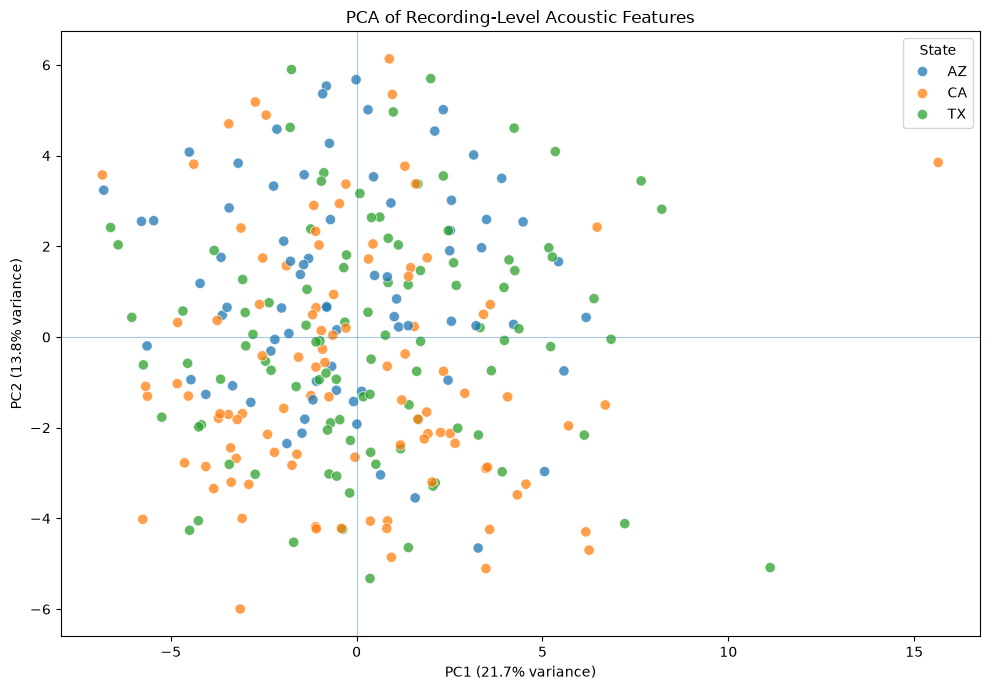

In [15]:
# ============================================================
# PCA VISUALIZATION — PC1 vs PC2
# ============================================================

pca_scores = pd.DataFrame(
    X_transformed_pca[:, :5],
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
    index=recording_features.index
)

# Add metadata ONLY for visualization/interpretation.
pca_scores["state"] = recording_features["state"].values
pca_scores["species_id"] = recording_features["species_id"].values
pca_scores["quality"] = (
    recording_features["flag_any"]
    .map({False: "Pass", True: "Flagged"})
)

print("=" * 70)
print("PCA SCORE SUMMARY")
print("=" * 70)

display(pca_scores.head())

# ------------------------------------------------------------
# PC1 vs PC2 colored by state
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="state",
    alpha=0.75,
    s=55
)

plt.axhline(0, linewidth=0.8, alpha=0.4)
plt.axvline(0, linewidth=0.8, alpha=0.4)

plt.title("PCA of Recording-Level Acoustic Features")
plt.xlabel(f"PC1 ({explained_transformed[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_transformed[1]*100:.1f}% variance)")
plt.legend(title="State")
plt.tight_layout()
plt.show()

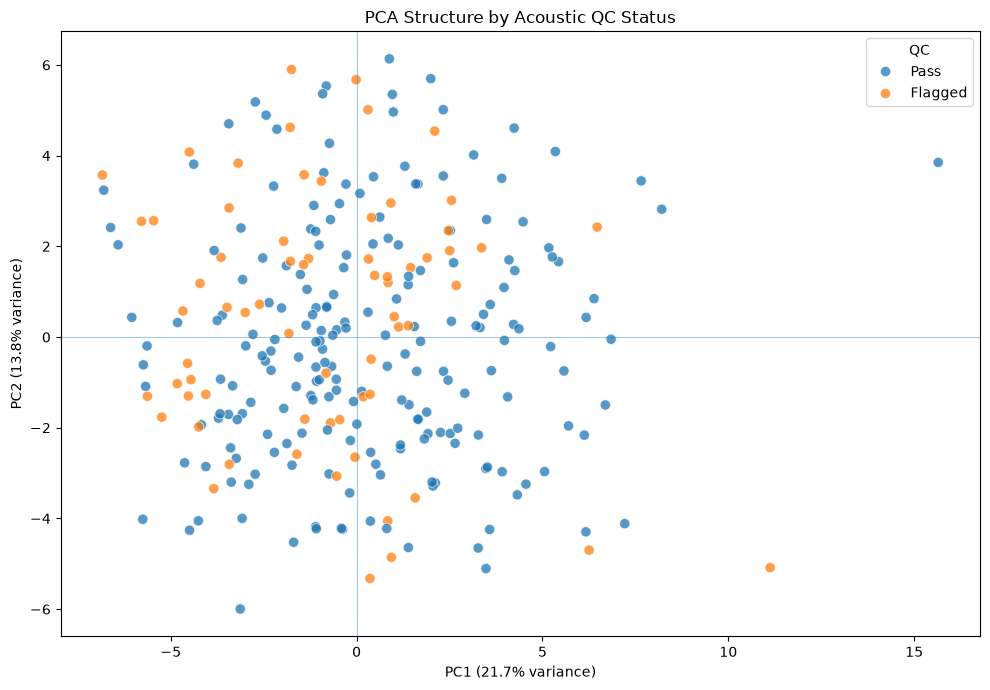

In [16]:
# ============================================================
# PC1 vs PC2 — QC STATUS
# ============================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="quality",
    alpha=0.75,
    s=55
)

plt.axhline(0, linewidth=0.8, alpha=0.4)
plt.axvline(0, linewidth=0.8, alpha=0.4)

plt.title("PCA Structure by Acoustic QC Status")
plt.xlabel(f"PC1 ({explained_transformed[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_transformed[1]*100:.1f}% variance)")
plt.legend(title="QC")
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# PCA STABILITY — RECORDING-LEVEL RESAMPLING
# ============================================================

N_BOOTSTRAPS = 200
N_COMPONENTS_STABILITY = 5

rng = np.random.default_rng(RANDOM_SEED)

reference_loadings = pca_transformed.components_[:N_COMPONENTS_STABILITY].copy()

bootstrap_correlations = {
    f"PC{i}": []
    for i in range(1, N_COMPONENTS_STABILITY + 1)
}

bootstrap_explained = []

for b in range(N_BOOTSTRAPS):

    # Resample recordings WITH replacement
    sample_idx = rng.integers(
        0,
        X_transformed_scaled.shape[0],
        size=X_transformed_scaled.shape[0]
    )

    X_boot = X_transformed_scaled[sample_idx]

    pca_boot = PCA(
        n_components=N_COMPONENTS_STABILITY,
        random_state=RANDOM_SEED
    )

    pca_boot.fit(X_boot)

    # Compare loading vectors.
    # PCA signs are arbitrary, so absolute correlation is used.
    for i in range(N_COMPONENTS_STABILITY):

        corr = np.corrcoef(
            reference_loadings[i],
            pca_boot.components_[i]
        )[0, 1]

        bootstrap_correlations[f"PC{i+1}"].append(abs(corr))

    bootstrap_explained.append(
        pca_boot.explained_variance_ratio_
    )

bootstrap_explained = np.array(bootstrap_explained)

# ------------------------------------------------------------
# Summarize loading stability
# ------------------------------------------------------------

stability_summary = pd.DataFrame({
    "PC": range(1, N_COMPONENTS_STABILITY + 1),
    "Median_Loading_Correlation": [
        np.median(bootstrap_correlations[f"PC{i}"])
        for i in range(1, N_COMPONENTS_STABILITY + 1)
    ],
    "5th_Percentile": [
        np.percentile(bootstrap_correlations[f"PC{i}"], 5)
        for i in range(1, N_COMPONENTS_STABILITY + 1)
    ],
    "95th_Percentile": [
        np.percentile(bootstrap_correlations[f"PC{i}"], 95)
        for i in range(1, N_COMPONENTS_STABILITY + 1)
    ]
})

print("=" * 70)
print("PCA LOADING STABILITY — BOOTSTRAP")
print("=" * 70)

display(stability_summary.round(4))

# ------------------------------------------------------------
# Explained variance stability
# ------------------------------------------------------------

variance_stability = pd.DataFrame({
    "PC": range(1, N_COMPONENTS_STABILITY + 1),
    "Original": explained_transformed[:N_COMPONENTS_STABILITY],
    "Bootstrap_Median": np.median(bootstrap_explained, axis=0),
    "Bootstrap_5th": np.percentile(
        bootstrap_explained, 5, axis=0
    ),
    "Bootstrap_95th": np.percentile(
        bootstrap_explained, 95, axis=0
    )
})

print("\n" + "=" * 70)
print("PCA EXPLAINED VARIANCE STABILITY")
print("=" * 70)

display(variance_stability.round(4))

PCA LOADING STABILITY — BOOTSTRAP


,PC,Median_Loading_Correlation,5th_Percentile,95th_Percentile
0,1,0.9733,0.9289,0.9912
1,2,0.9730,0.9438,0.9893
2,3,0.8695,0.3874,0.9696
3,4,0.7763,0.0751,0.9461
4,5,0.6337,0.0865,0.8949



PCA EXPLAINED VARIANCE STABILITY


,PC,Original,Bootstrap_Median,Bootstrap_5th,Bootstrap_95th
0,1,0.2167,0.2219,0.2013,0.2550
1,2,0.1384,0.1411,0.1262,0.1557
2,3,0.0756,0.0806,0.0715,0.0924
3,4,0.0638,0.0678,0.0607,0.0755
4,5,0.0565,0.0581,0.0513,0.0644
